# Modelling and Small-Data Machine Learning Pipeline for LMD

**objective:** Prepare the processed dataset for ML, Perform scaling, transformations, feature selection, multicolinearity checks, applying baseline linear regression, residual analysis and validation suitable for small data. 

In [5]:
# import libraries

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_validate, train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
import statsmodels.api as sm




# Load data and selecting features


In [6]:
# Loading the dataset

df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")


target = "porosity_%" # change to other targets as needed

# use core process parameters  as inputs (avoid LED/VED to reduce multicolinearity)
features = ["Power","Speed", "Feed"] 

X = df[features].copy()
y = df[target].copy()

print("Features shape: ", X.shape)
print("Target shape")

Features shape:  (89, 3)
Target shape


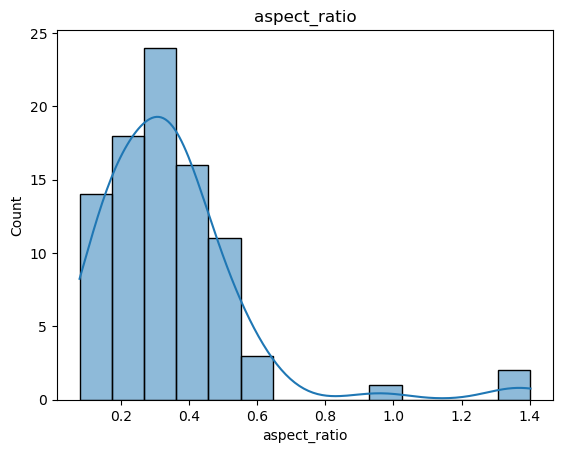

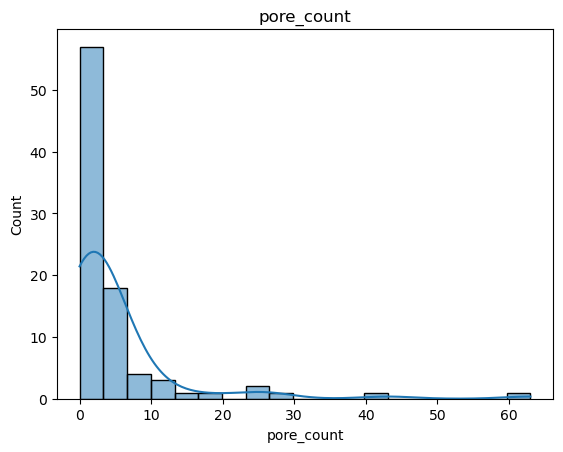

In [7]:
num_col = ["aspect_ratio", "pore_count" ]

for col in num_col:
    plt.figure()
    sns.histplot(df[col], kde = True)
    plt.title(col)

## Multicollinearity Check (VIF Analysis)
When two or more predictor (input) variables in a regression model carry almost the same information because they are strongly linearly correlated with each other.

Variance Inflation Factor (VIF): for each predictor , fit a regression of that predictor on all the others and compute.

Interpretation guidance :

VIF > 10 → severe multicollinearity, remove or combine features

VIF 5–10 → moderate, monitor

VIF < 5 → acceptable

In [14]:
#Check for multicollinearirty
# #from statsmodels.stats.outliers_influence import variance_inflation_factor
def compute_vif(X):
    vif_df = pd.DataFrame()
    vif_df["feature"] = X.columns
    vif_df["VIF"] = [
        variance_inflation_factor(X.values, i)
        for i in range(len(X.columns))
    ]
    return vif_df

compute_vif(X)


,feature,VIF
0,Power,14.227862
1,Speed,10.482437
2,Feed,5.676945


# Train/test split and scaling


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) 

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

print("Train size: ", X_train_scaled.shape[0], "| Test size:", X_test_scaled.shape[0])

Train size:  71 | Test size: 18


# Fit linear regression model

In [16]:

# Define models

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Predictions

y_train_pred = lr_model.predict(X_train_scaled)
y_test_pred = lr_model.predict(X_test_scaled)
# --- IGNORE ---



In [17]:
# Defining models with regulirat parameters
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),   # Try alpha  = 0.1, 1.0, 10.0
    "Lasso": Lasso(alpha=0.1),    # Try alpha = 0.01, 0.1, 1.0
    "RidgeCV": RidgeCV(alphas=[0.1, 1.0, 10.0]),
    "LassoCV": LassoCV(cv=5)
}
"""Note on alpha:

Ridge/Lasso α controls regularization strength (higher α → more shrinkage).

Start with α=1.0 for Ridge, α=0.01 for Lasso; tune later if needed.
"""

'Note on alpha:\n\nRidge/Lasso α controls regularization strength (higher α → more shrinkage).\n\nStart with α=1.0 for Ridge, α=0.01 for Lasso; tune later if needed.\n'

## Model coefficients and interpretation


In [19]:
# Fit models and collect results
results = {}

for name, model in models.items():
    #fit the model
    model.fit(X_train_scaled, y_train)

    #make predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)

    # Metrics

    results[name] = {
        "R2_train": r2_score(y_train, y_train_pred),
        "R2_test": r2_score(y_test, y_test_pred),
        "RMSE_train": np.sqrt(mean_squared_error(y_train, y_train_pred)),
        "RMSE_test": np.sqrt(mean_squared_error(y_test, y_test_pred)),
        "MAE_train": mean_absolute_error(y_train, y_train_pred),
        "MAE_test": mean_absolute_error(y_test, y_test_pred),
        "MSE_train": mean_squared_error(y_train, y_train_pred),
        "MSE_test": mean_squared_error(y_test, y_test_pred)
    }

# convert results to DataFrame for better visualization
results_df = pd.DataFrame(results).T
print(results_df)

                   R2_train   R2_test  RMSE_train  RMSE_test  MAE_train  \
Linear Regression  0.434414 -5.134287    0.377224   0.355202   0.227305   
Ridge              0.434352 -5.061320    0.377244   0.353084   0.226165   
Lasso              0.331387 -3.265564    0.410144   0.296198   0.226555   
RidgeCV            0.429376 -4.518027    0.378900   0.336888   0.217930   
LassoCV            0.433298 -4.849271    0.377595   0.346852   0.223089   

                   MAE_test  MSE_train  MSE_test  
Linear Regression  0.313244   0.142298  0.126169  
Ridge              0.311994   0.142313  0.124668  
Lasso              0.260383   0.168218  0.087733  
RidgeCV            0.301923   0.143565  0.113494  
LassoCV            0.307513   0.142578  0.120307  


In [20]:
# cross validation for robustness check
cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}

for name, model in models.items():
    # Fit scaler + model in apipeline for a proper CV
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])  

    #cross validate
    scores = cross_validate(
        pipe, X, y, cv=cv,
        scoring= {
            "r2": "r2",
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error"
        },

        return_train_score= False
    )
    cv_results[name] = {
        "R2_CV_mean": scores["test_r2"].mean(),
        "R2_CV_std": scores["test_r2"].std(),
        "RMSE_CV_mean": -scores["test_rmse"].mean(),
        "RMSE_CV_std": scores["test_rmse"].std(),
        "MAE_CV_mean": -scores["test_mae"].mean(),
        "MAE_CV_std": scores["test_mae"].std(),
        "MSE_CV_mean": -scores["test_mse"].mean(),
        "MSE_CV_std": scores["test_mse"].std()
    }

cv_results_df = pd.DataFrame(cv_results).T
print("\n--- Cross-Validation Results ---")
print(cv_results_df)


--- Cross-Validation Results ---
                   R2_CV_mean  R2_CV_std  RMSE_CV_mean  RMSE_CV_std  \
Linear Regression   -0.640766   2.091335      0.362698     0.155305   
Ridge               -0.625343   2.062837      0.362212     0.155898   
Lasso               -0.434255   1.284859      0.396584     0.170169   
RidgeCV             -0.512581   1.851020      0.358398     0.157190   
LassoCV             -0.639382   2.088480      0.362673     0.155350   

                   MAE_CV_mean  MAE_CV_std  MSE_CV_mean  MSE_CV_std  
Linear Regression     0.242006    0.056547     0.155670    0.140023  
Ridge                 0.240800    0.056589     0.155502    0.140645  
Lasso                 0.242467    0.050215     0.186237    0.168141  
RidgeCV               0.233621    0.059242     0.153158    0.141461  
LassoCV               0.241910    0.056539     0.155666    0.140072  


In [21]:
# VISIUALIZE COEFFICIENT COMPARIONS
# Extract coefficients
coef_comparison = pd.DataFrame({
    "Feature": X.columns,
    "LinearRegression": models["OLS"].coef_,
    "Ridge": models["Ridge"].coef_,
    "Lasso": models["Lasso"].coef_
})

print(coef_comparison)

# Plot
coef_comparison.set_index("Feature").plot(kind="bar", figsize=(8, 5))
plt.ylabel("Coefficient value")
plt.title("Coefficient Comparison: OLS vs Ridge vs Lasso")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.legend()
plt.tight_layout()
plt.show()


KeyError: 'OLS'

In [17]:
coef_df = pd.DataFrame({
    'feature': features,
    'coefficient': lr_model.coef_
})

coef_df["intercept"] = lr_model.intercept_  
print(coef_df)  


  feature  coefficient  intercept
0   Power   -51.158212  816.99969
1   Speed  -231.252002  816.99969
2    Feed   306.496266  816.99969


## Performance Metrics

In [18]:
def evaluate_model(y_true, y_pred, dataset_name = ""):
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    r2 = lr_model.score(X_test_scaled, y_test)
    
    print(f"Evaluation Metrics for {dataset_name} dataset:")
    print(f"RMSE: {rmse:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R^2: {r2:.4f}")
    print("\n")
    
    return {"RMSE": rmse, "MSE": mse, "MAE": mae, "R2": r2}

train_metrics = evaluate_model(y_train, y_train_pred, dataset_name="Training Set")
test_metrics = evaluate_model(y_test, y_test_pred, dataset_name="Testing Set")         

Evaluation Metrics for Training Set dataset:
RMSE: 158.2080
MSE: 25029.7596
MAE: 115.0935
R^2: 0.8878


Evaluation Metrics for Testing Set dataset:
RMSE: 122.0859
MSE: 14904.9717
MAE: 99.7387
R^2: 0.8878




# Cross validation for robust estimates



In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Note: cross_val_score uses negative MSE by default for scoring
"""
cv_rmse = -cross_val_score(
    lr_model,scaler.fit_transform(X), y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True
)   
cv_r2 = cross_val_score(
    lr_model,scaler.fit_transform(X), y, cv=cv, scoring="r2", return_train_score=True
)

print("Cross-Validation Results:")
print(f"Average Train RMSE: {np.mean(np.sqrt(cv_rmse['train_score'])):.4f}")
print(f"Average Test RMSE: {np.mean(np.sqrt(cv_rmse['test_score'])):.4f}")
print(f"Average Train R^2: {np.mean(cv_r2['train_score']):.4f}")
print(f"Average Test R^2: {np.mean(cv_r2['test_score']):.4f}")  
"""

'\ncv_rmse = -cross_val_score(\n    lr_model,scaler.fit_transform(X), y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True\n)   \ncv_r2 = cross_val_score(\n    lr_model,scaler.fit_transform(X), y, cv=cv, scoring="r2", return_train_score=True\n)\n\nprint("Cross-Validation Results:")\nprint(f"Average Train RMSE: {np.mean(np.sqrt(cv_rmse[\'train_score\'])):.4f}")\nprint(f"Average Test RMSE: {np.mean(np.sqrt(cv_rmse[\'test_score\'])):.4f}")\nprint(f"Average Train R^2: {np.mean(cv_r2[\'train_score\']):.4f}")\nprint(f"Average Test R^2: {np.mean(cv_r2[\'test_score\']):.4f}")  \n'

In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Note: cross_val_score uses neg_mean_squared_error
cv_rmse = -cross_val_score(lr_model, scaler.fit_transform(X), y, cv=cv, scoring="neg_root_mean_squared_error")
cv_r2 = cross_val_score(lr_model, scaler.fit_transform(X), y, cv=cv, scoring="r2")

print(f"5-Fold CV RMSE: {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}")
print(f"5-Fold CV R²:   {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")


NameError: name 'KFold' is not defined

# Model Diagnostics: Checking Linear regression Asssumptions


In [19]:
# Compute resuduals
residuals_train = y_train - y_train_pred
residuals_test = y_test - y_test_pred


In [2]:
# Residuals vs Fitted
plt.figure(figsize=(8, 5))
plt.scatter(y_train_pred, residuals_train, alpha=0.7, edgecolors="k")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted)")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (Training Set)")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
plt.scatter(y_test_pred, residuals_test, alpha=0.7, edgecolors="k")
plt.axhline(0, color="red", linestyle="--")


NameError: name 'plt' is not defined

What to look for:

Linearity: residuals should scatter randomly around zero with no clear curve.

Homoscedasticity: spread of residuals should be roughly constant across fitted values (no funnel shape).

In [1]:
#Q-Q Plot (Normality of Residuals)
fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(residuals_train, dist="norm", plot=ax)
ax.set_title("Q-Q Plot of Residuals (Training Set)")
plt.tight_layout()
plt.show()


NameError: name 'plt' is not defined

What to look for:

Points should fall approximately along the diagonal line.

Deviations at the tails suggest heavy tails or skewness.




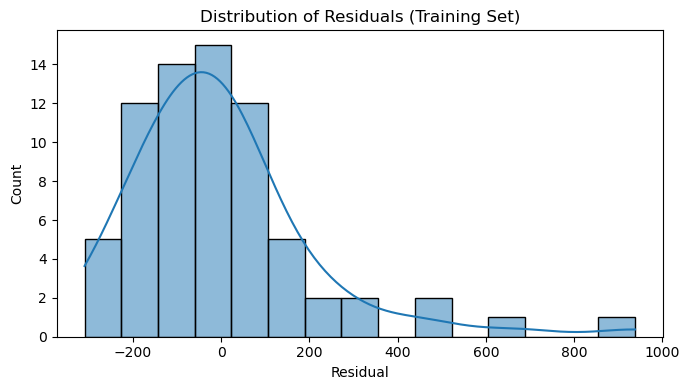

In [20]:
# Histogram of Residuals
plt.figure(figsize=(7, 4))
sns.histplot(residuals_train, kde=True, bins=15)
plt.xlabel("Residual")
plt.title("Distribution of Residuals (Training Set)")
plt.tight_layout()
plt.show()
#plt.xlabel("Fitted values (predicted)")
#plt.ylabel("Residuals")
#plt.title("Residuals vs Fitted (Testing Set)")
#plt.tight_layout()
#plt.show()          

What to look for: Approximately bell-shaped and centred near zero.

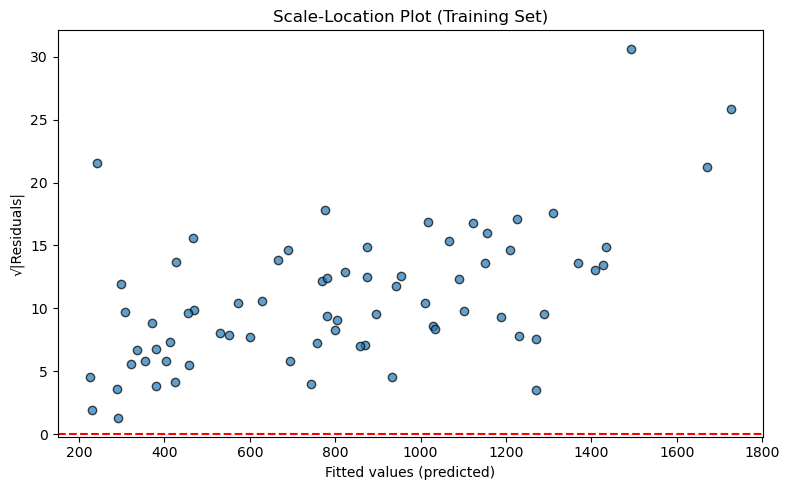

In [21]:
# Scale-Location plot (√|Residuals| vs Fitted)
plt.figure(figsize=(8, 5))
plt.scatter(y_train_pred, np.sqrt(np.abs(residuals_train)), alpha=0.7, edgecolors="k")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted)")
plt.ylabel("√|Residuals|")
plt.title("Scale-Location Plot (Training Set)")
plt.tight_layout()
plt.show()

What to look for: A flat trend line confirms homoscedasticity; an upward/downward trend indicates heteroscedasticity.

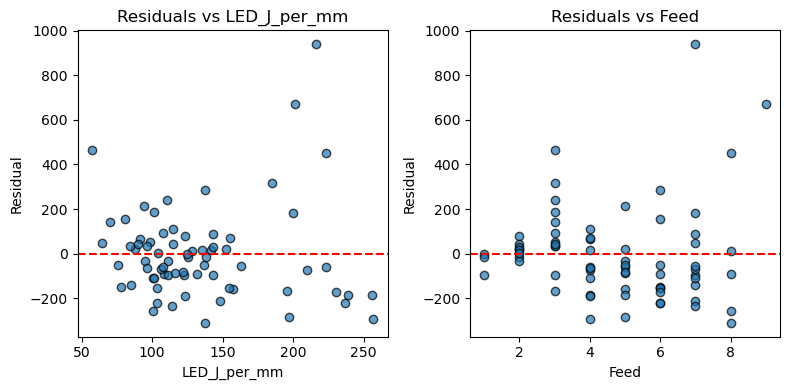

In [22]:
# Residuals vs each predictor (independence check)
fig, axes = plt.subplots(1, len(features), figsize=(4*len(features), 4))

for i, col in enumerate(features):
    axes[i].scatter(X_train[col], residuals_train, alpha=0.7, edgecolors="k")
    axes[i].axhline(0, color="red", linestyle="--")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Residual")
    axes[i].set_title(f"Residuals vs {col}")

plt.tight_layout()
plt.show()



What to look for: No systematic pattern; random scatter around zero for each predictor.

In [25]:
# Statsmodels OLS summary (detailed statistics)
X_train_sm = sm.add_constant(X_train_scaled)
ols_model = sm.OLS(y_train, X_train_sm).fit()
print(ols_model.summary())



                            OLS Regression Results                            
Dep. Variable:              height_um   R-squared:                       0.772
Model:                            OLS   Adj. R-squared:                  0.766
Method:                 Least Squares   F-statistic:                     115.4
Date:                Thu, 22 Jan 2026   Prob (F-statistic):           1.39e-22
Time:                        00:22:06   Log-Likelihood:                -480.27
No. Observations:                  71   AIC:                             966.5
Df Residuals:                      68   BIC:                             973.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        816.9997     25.423     32.137      0.0

This gives you:

p-values for each coefficient (statistical significance).

Adjusted R² (penalises extra features).

F-statistic (overall model significance).

Durbin-Watson (checks autocorrelation in residuals; ~2 is ideal).

Condition number (high values indicate multicollinearity).

In [26]:
# Compile results

results = pd.DataFrame({
    "Metric": ["R²", "RMSE", "MSE", "MAE"],
    "Train": [train_metrics["R2"], train_metrics["RMSE"], train_metrics["MSE"], train_metrics["MAE"]],
    "Test": [test_metrics["R2"], test_metrics["RMSE"], test_metrics["MSE"], test_metrics["MAE"]],
    "CV Mean": [cv_r2.mean(), cv_rmse.mean(), cv_rmse.mean()**2, np.nan]
})
print(results.to_string(index=False))


Metric        Train         Test      CV Mean
    R²     0.783369     0.783369     0.755380
  RMSE   209.639826   169.669208   202.181640
   MSE 43948.856468 28787.640286 40877.415737
   MAE   144.388055   136.847846          NaN


# How to interpret results 
| Diagnostic          | What it checks              | Good result               | Action if violated                                               |
| ------------------- | --------------------------- | ------------------------- | ---------------------------------------------------------------- |
| VIF                 | Multicollinearity           | VIF < 5–10                | Drop or combine correlated features                              |
| Residuals vs Fitted | Linearity, homoscedasticity | Random scatter, no funnel | Consider polynomial terms, transformations, or non-linear models |
| Q–Q plot            | Normality of residuals      | Points on diagonal        | Check for outliers; consider robust regression                   |
| Durbin-Watson       | Independence of errors      | Close to 2                | Investigate if data has ordering/time component                  |
| p-values            | Coefficient significance    | p < 0.05                  | Remove non-significant features or justify retention             |